In [ ]:
!pip -q install datasets pandas

In [ ]:
from datasets import load_dataset

# IMDb dataset Hugging Face se load karein
dataset = load_dataset("stanfordnlp/imdb")

# Dataset ka size check karein
print(dataset)

# Ek review dekhein
print("\nSample review:")
print(dataset["train"][0]["text"])

print("\nSentiment label:")
print(dataset["train"][0]["label"])


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

Sample review:
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicia

In [ ]:
import pandas as pd

# Hugging Face dataset ko DataFrame mein convert karein
train_df = dataset["train"].to_pandas()
test_df = dataset["test"].to_pandas()

# Dataset ka size
print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

# Positive aur negative reviews ka count
print("\nTraining sentiment distribution:")
print(train_df["label"].value_counts().sort_index())

print("\nTesting sentiment distribution:")
print(test_df["label"].value_counts().sort_index())

# Labels ko readable banayein
print("\nSample reviews with sentiment:")
train_df["sentiment"] = train_df["label"].map({
    0: "Negative",
    1: "Positive"
})

display(train_df[["text", "sentiment"]].head(5))


Training shape: (25000, 2)
Testing shape: (25000, 2)

Training sentiment distribution:
label
0    12500
1    12500
Name: count, dtype: int64

Testing sentiment distribution:
label
0    12500
1    12500
Name: count, dtype: int64

Sample reviews with sentiment:


,text,sentiment
0,I rented I AM CURIOUS-YELLOW from my video sto...,Negative
1,"""I Am Curious: Yellow"" is a risible and preten...",Negative
2,If only to avoid making this type of film in t...,Negative
3,This film was probably inspired by Godard's Ma...,Negative
4,"Oh, brother...after hearing about this ridicul...",Negative


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import time

# Reviews aur labels alag karein
X_train = train_df["text"].fillna("")
y_train = train_df["label"]

X_test = test_df["text"].fillna("")
y_test = test_df["label"]

# TF-IDF + Logistic Regression baseline
baseline_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=50000,
        ngram_range=(1, 1),
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Model train karein
start_time = time.time()
baseline_model.fit(X_train, y_train)
training_time = time.time() - start_time

# Test data par prediction
y_pred = baseline_model.predict(X_test)

# Results
baseline_accuracy = accuracy_score(y_test, y_pred)

print(f"Baseline Accuracy: {baseline_accuracy * 100:.2f}%")
print(f"Training Time: {training_time:.2f} seconds")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Baseline Accuracy: 88.90%
Training Time: 18.36 seconds

Classification Report:
              precision    recall  f1-score   support

    Negative       0.89      0.89      0.89     12500
    Positive       0.89      0.89      0.89     12500

    accuracy                           0.89     25000
   macro avg       0.89      0.89      0.89     25000
weighted avg       0.89      0.89      0.89     25000

Confusion Matrix:
[[11096  1404]
 [ 1371 11129]]


In [ ]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report
import time

bigram_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=50000,
        ngram_range=(1, 2),
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

start_time = time.time()

bigram_model.fit(X_train, y_train)

bigram_training_time = time.time() - start_time

bigram_pred = bigram_model.predict(X_test)

bigram_accuracy = accuracy_score(y_test, bigram_pred)

print(f"TF-IDF Unigrams + Bigrams Accuracy: {bigram_accuracy * 100:.2f}%")
print(f"Training Time: {bigram_training_time:.2f} seconds")
print("\nClassification Report:")
print(classification_report(
    y_test,
    bigram_pred,
    target_names=["Negative", "Positive"]
))


TF-IDF Unigrams + Bigrams Accuracy: 90.02%
Training Time: 23.76 seconds

Classification Report:
              precision    recall  f1-score   support

    Negative       0.90      0.90      0.90     12500
    Positive       0.90      0.90      0.90     12500

    accuracy                           0.90     25000
   macro avg       0.90      0.90      0.90     25000
weighted avg       0.90      0.90      0.90     25000



In [ ]:

optimized_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=100000,
        ngram_range=(1, 2),
        sublinear_tf=True,
        min_df=2,
        max_df=0.95
    )),
    ("classifier", LogisticRegression(
        C=1.0,
        max_iter=1000,
        random_state=42
    ))
])

start_time = time.time()

optimized_model.fit(X_train, y_train)

optimized_training_time = time.time() - start_time

optimized_pred = optimized_model.predict(X_test)

optimized_accuracy = accuracy_score(y_test, optimized_pred)

print(f"Optimized TF-IDF Accuracy: {optimized_accuracy * 100:.2f}%")
print(f"Training Time: {optimized_training_time:.2f} seconds")
print("\nClassification Report:")
print(classification_report(
    y_test,
    optimized_pred,
    target_names=["Negative", "Positive"]
))


Optimized TF-IDF Accuracy: 89.96%
Training Time: 32.18 seconds

Classification Report:
              precision    recall  f1-score   support

    Negative       0.90      0.90      0.90     12500
    Positive       0.90      0.90      0.90     12500

    accuracy                           0.90     25000
   macro avg       0.90      0.90      0.90     25000
weighted avg       0.90      0.90      0.90     25000



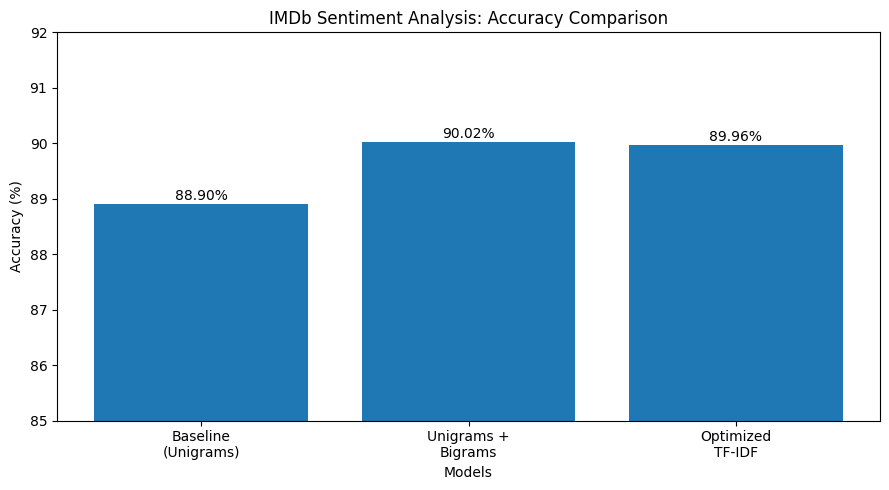

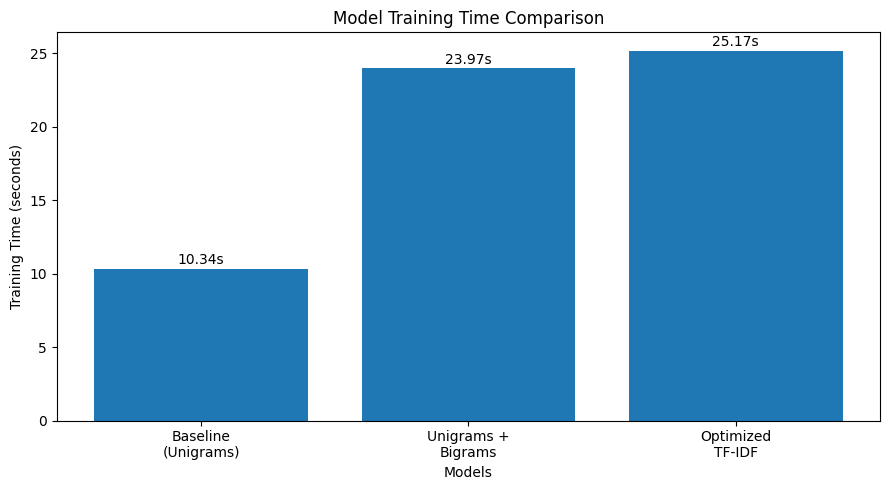

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

# Actual results from your experiments
model_names = [
    "Baseline\n(Unigrams)",
    "Unigrams +\nBigrams",
    "Optimized\nTF-IDF"
]

accuracies = [88.90, 90.02, 89.96]
training_times = [10.34, 23.97, 25.17]

# Graph 1: Accuracy comparison
plt.figure(figsize=(9, 5))
bars = plt.bar(model_names, accuracies)

plt.title("IMDb Sentiment Analysis: Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.ylim(85, 92)
plt.xlabel("Models")

for bar, value in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.08,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

# Graph 2: Training time comparison
plt.figure(figsize=(9, 5))
bars = plt.bar(model_names, training_times)

plt.title("Model Training Time Comparison")
plt.ylabel("Training Time (seconds)")
plt.xlabel("Models")

for bar, value in zip(bars, training_times):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.3,
        f"{value:.2f}s",
        ha="center"
    )

plt.tight_layout()
plt.show()



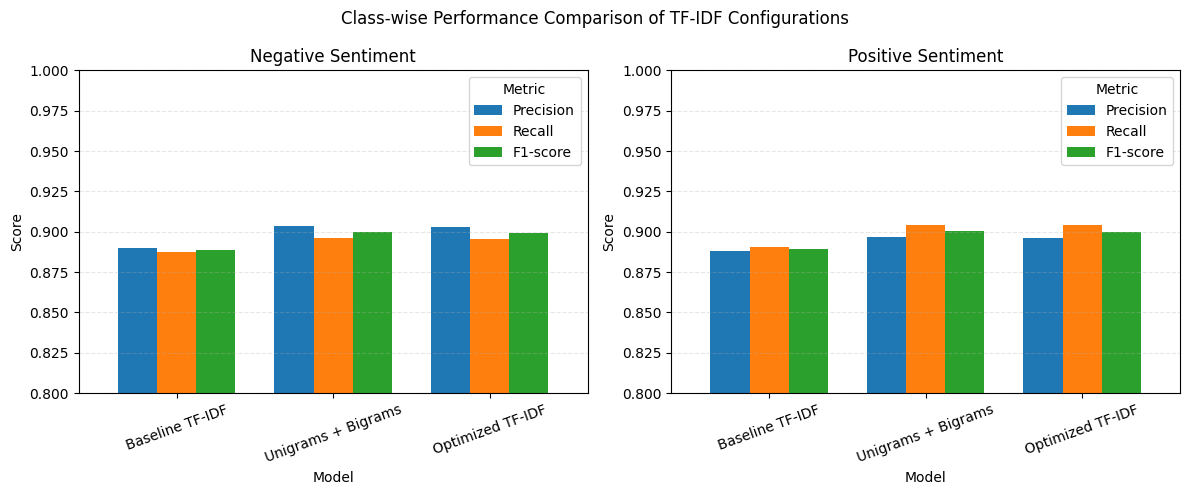

Graph saved to: /content/imdb_classwise_performance.png


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Read the uploaded CSV file
df = pd.read_csv("/content/imdb_classwise_metrics.csv")

# Check that the required columns exist
required = ["Model", "Sentiment", "Precision", "Recall", "F1-score"]
if not all(col in df.columns for col in required):
    raise ValueError(f"CSV must contain these columns: {required}")

# Create a class-wise performance graph
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

metrics = ["Precision", "Recall", "F1-score"]
sentiments = ["Negative", "Positive"]

for ax, sentiment in zip(axes, sentiments):
    data = df[df["Sentiment"].str.lower() == sentiment.lower()]
    data = data.set_index("Model")[metrics]

    data.plot(kind="bar", ax=ax, width=0.75)
    ax.set_title(f"{sentiment} Sentiment")
    ax.set_ylabel("Score")
    ax.set_xlabel("Model")
    ax.set_ylim(0.80, 1.00)
    ax.legend(title="Metric")
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.suptitle("Class-wise Performance Comparison of TF-IDF Configurations")
plt.tight_layout()

# Save the graph as a high-resolution PNG
output_file = "/content/imdb_classwise_performance.png"
plt.savefig(output_file, dpi=300, bbox_inches="tight")
plt.show()

print("Graph saved to:", output_file)


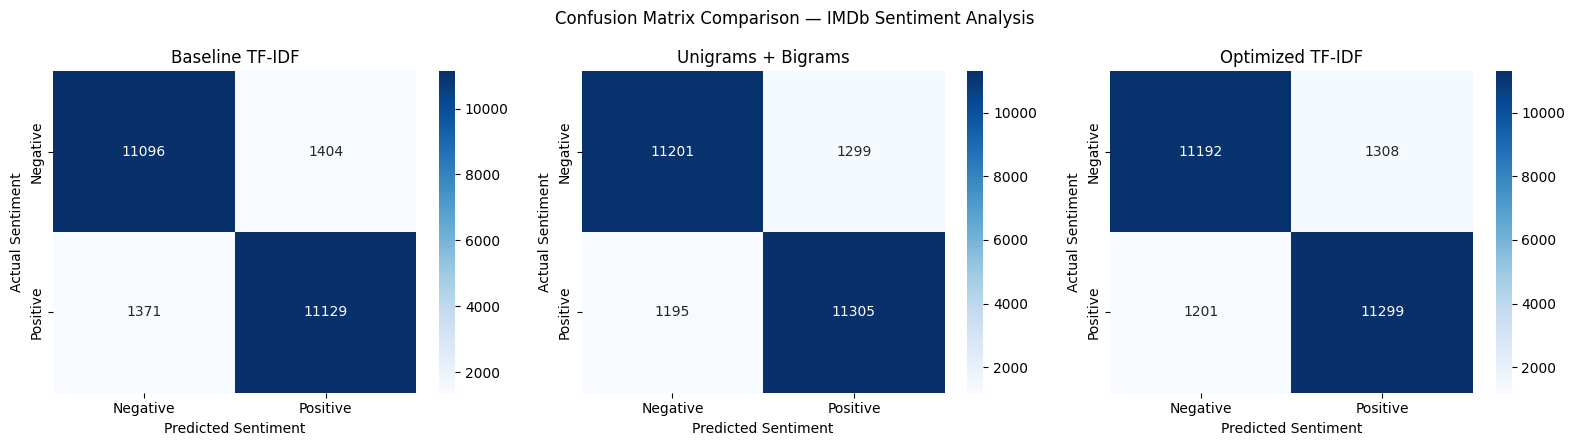

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Predictions already created in previous cells
models = [
    ("Baseline TF-IDF", y_pred),
    ("Unigrams + Bigrams", bigram_pred),
    ("Optimized TF-IDF", optimized_pred)
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (name, predictions) in zip(axes, models):
    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Sentiment")
    ax.set_ylabel("Actual Sentiment")

plt.suptitle("Confusion Matrix Comparison — IMDb Sentiment Analysis")
plt.tight_layout()
plt.show()


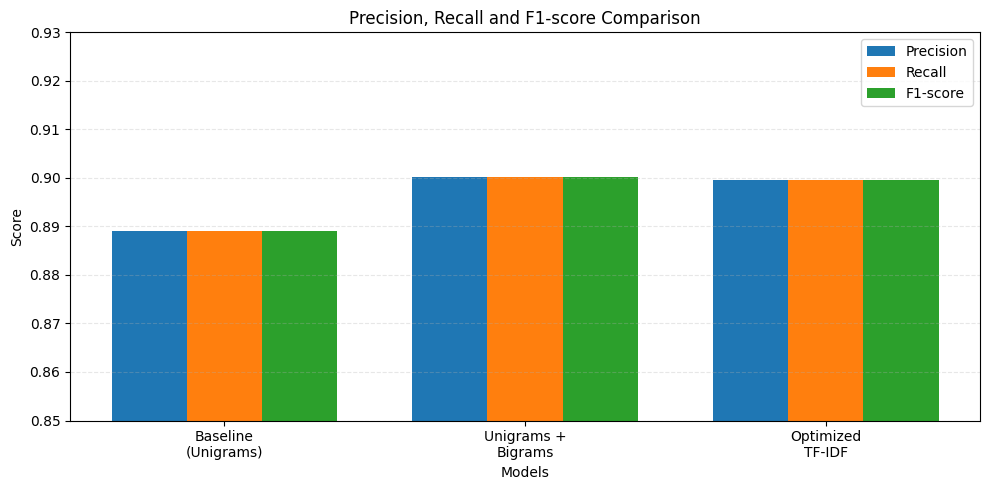

Weighted classification metrics:
Baseline (Unigrams): Precision=0.8890, Recall=0.8890, F1-score=0.8890
Unigrams + Bigrams: Precision=0.9003, Recall=0.9002, F1-score=0.9002
Optimized TF-IDF: Precision=0.8997, Recall=0.8996, F1-score=0.8996


In [ ]:

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

# Actual predictions from your three trained models
model_names = [
    "Baseline\n(Unigrams)",
    "Unigrams +\nBigrams",
    "Optimized\nTF-IDF"
]

predictions = [y_pred, bigram_pred, optimized_pred]

precision_values = []
recall_values = []
f1_values = []

for pred in predictions:
    precision_values.append(
        precision_score(y_test, pred, average="weighted")
    )
    recall_values.append(
        recall_score(y_test, pred, average="weighted")
    )
    f1_values.append(
        f1_score(y_test, pred, average="weighted")
    )

x = np.arange(len(model_names))
width = 0.25

plt.figure(figsize=(10, 5))

plt.bar(x - width, precision_values, width, label="Precision")
plt.bar(x, recall_values, width, label="Recall")
plt.bar(x + width, f1_values, width, label="F1-score")

plt.title("Precision, Recall and F1-score Comparison")
plt.ylabel("Score")
plt.xlabel("Models")
plt.xticks(x, model_names)
plt.ylim(0.85, 0.93)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

print("Weighted classification metrics:")
for i, name in enumerate(model_names):
    print(
        f"{name.replace(chr(10), ' ')}: "
        f"Precision={precision_values[i]:.4f}, "
        f"Recall={recall_values[i]:.4f}, "
        f"F1-score={f1_values[i]:.4f}"
    )


In [ ]:

import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

model_names = [
    "Baseline TF-IDF (Unigrams)",
    "TF-IDF (Unigrams + Bigrams)",
    "Optimized TF-IDF"
]

predictions = [y_pred, bigram_pred, optimized_pred]
training_times = [
    training_time,
    bigram_training_time,
    optimized_training_time
]

results = []

for name, pred, train_time in zip(
    model_names, predictions, training_times
):
    results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy_score(y_test, pred) * 100, 2),
        "Precision": round(precision_score(y_test, pred, average="weighted"), 4),
        "Recall": round(recall_score(y_test, pred, average="weighted"), 4),
        "F1-score": round(f1_score(y_test, pred, average="weighted"), 4),
        "Training Time (seconds)": round(train_time, 2)
    })

results_df = pd.DataFrame(results)

display(results_df)

# Save results for later use in the research paper
results_df.to_csv("imdb_model_comparison.csv", index=False)

print("Results saved to imdb_model_comparison.csv")


,Model,Accuracy (%),Precision,Recall,F1-score,Training Time (seconds)
0,Baseline TF-IDF (Unigrams),88.90,0.8890,0.8890,0.8890,18.36
1,TF-IDF (Unigrams + Bigrams),90.02,0.9003,0.9002,0.9002,23.76
2,Optimized TF-IDF,89.96,0.8997,0.8996,0.8996,32.18


Results saved to imdb_model_comparison.csv


In [ ]:

from google.colab import files

files.download("imdb_model_comparison.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from sklearn.metrics import classification_report
import pandas as pd

model_predictions = {
    "Baseline TF-IDF": y_pred,
    "Unigrams + Bigrams": bigram_pred,
    "Optimized TF-IDF": optimized_pred
}

class_results = []

for model_name, predictions in model_predictions.items():
    report = classification_report(
        y_test,
        predictions,
        target_names=["Negative", "Positive"],
        output_dict=True
    )

    for sentiment in ["Negative", "Positive"]:
        class_results.append({
            "Model": model_name,
            "Sentiment": sentiment,
            "Precision": round(report[sentiment]["precision"], 4),
            "Recall": round(report[sentiment]["recall"], 4),
            "F1-score": round(report[sentiment]["f1-score"], 4)
        })

class_results_df = pd.DataFrame(class_results)

display(class_results_df)

class_results_df.to_csv(
    "imdb_classwise_metrics.csv",
    index=False
)

print("Class-wise metrics saved successfully.")


,Model,Sentiment,Precision,Recall,F1-score
0,Baseline TF-IDF,Negative,0.8900,0.8877,0.8889
1,Baseline TF-IDF,Positive,0.8880,0.8903,0.8891
2,Unigrams + Bigrams,Negative,0.9036,0.8961,0.8998
3,Unigrams + Bigrams,Positive,0.8969,0.9044,0.9007
4,Optimized TF-IDF,Negative,0.9031,0.8954,0.8992
5,Optimized TF-IDF,Positive,0.8962,0.9039,0.9001


Class-wise metrics saved successfully.


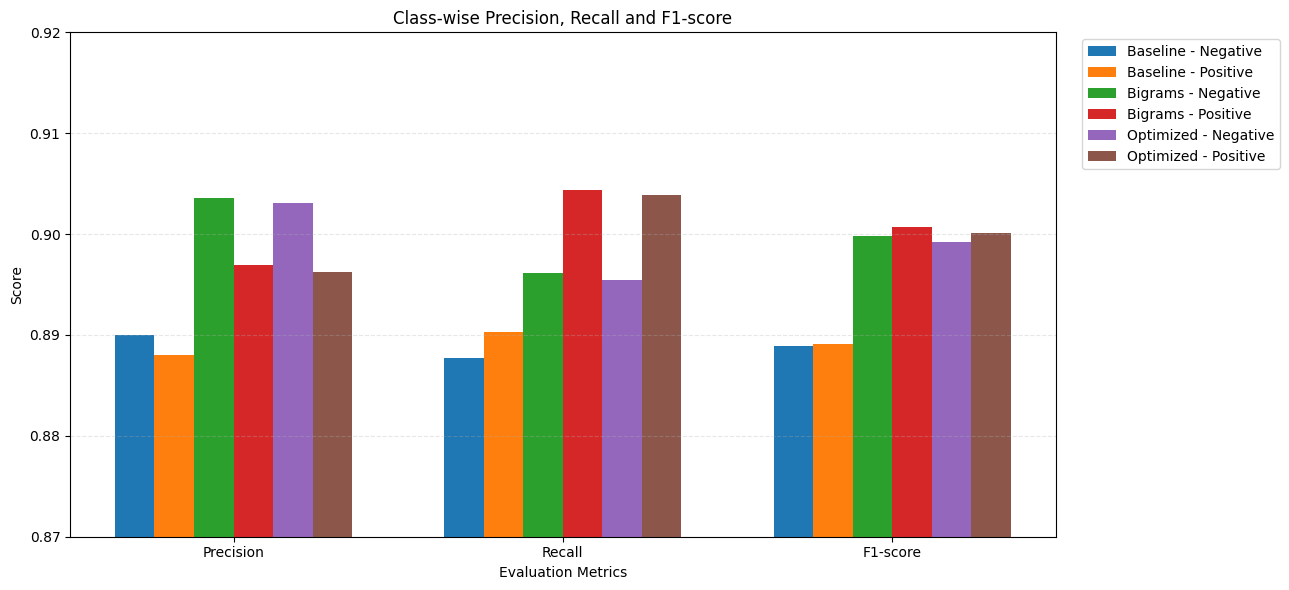

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

metrics = ["Precision", "Recall", "F1-score"]

class_metrics = {
    "Baseline - Negative": [0.8900, 0.8877, 0.8889],
    "Baseline - Positive": [0.8880, 0.8903, 0.8891],
    "Bigrams - Negative": [0.9036, 0.8961, 0.8998],
    "Bigrams - Positive": [0.8969, 0.9044, 0.9007],
    "Optimized - Negative": [0.9031, 0.8954, 0.8992],
    "Optimized - Positive": [0.8962, 0.9039, 0.9001]
}

x = np.arange(len(metrics))
width = 0.12

plt.figure(figsize=(13, 6))

for i, (name, values) in enumerate(class_metrics.items()):
    offset = (i - 2.5) * width
    plt.bar(x + offset, values, width, label=name)

plt.title("Class-wise Precision, Recall and F1-score")
plt.ylabel("Score")
plt.xlabel("Evaluation Metrics")
plt.xticks(x, metrics)
plt.ylim(0.87, 0.92)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:

# Test the best-performing model on new movie reviews

new_reviews = [
    "This movie was fantastic. The acting was excellent and the story was very engaging.",
    "This film was boring and disappointing. The acting was poor and the story was terrible.",
    "The movie was okay, but some scenes were too slow."
]

predictions = bigram_model.predict(new_reviews)

for review, prediction in zip(new_reviews, predictions):
    sentiment = "Positive" if prediction == 1 else "Negative"

    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print("-" * 70)


Review: This movie was fantastic. The acting was excellent and the story was very engaging.
Predicted Sentiment: Positive
----------------------------------------------------------------------
Review: This film was boring and disappointing. The acting was poor and the story was terrible.
Predicted Sentiment: Negative
----------------------------------------------------------------------
Review: The movie was okay, but some scenes were too slow.
Predicted Sentiment: Negative
----------------------------------------------------------------------


In [ ]:

from google.colab import files

# Save model comparison results
results_df.to_csv("imdb_model_comparison.csv", index=False)

# Download the results table
files.download("imdb_model_comparison.csv")



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from google.colab import files

class_results_df.to_csv("imdb_classwise_metrics.csv", index=False)
files.download("imdb_classwise_metrics.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Step 2: Check existing model results
from sklearn.metrics import accuracy_score

print("Baseline Model Accuracy:", accuracy_score(y_test, baseline_model.predict(X_test)))

print("Bigram Model Accuracy:", accuracy_score(y_test, bigram_model.predict(X_test)))

print("Optimized Model Accuracy:", accuracy_score(y_test, optimized_model.predict(X_test)))

Baseline Model Accuracy: 0.889
Bigram Model Accuracy: 0.90024
Optimized Model Accuracy: 0.89964


In [ ]:

from sklearn.metrics import classification_report

# Evaluate the best-performing Bigram Model
y_pred_bigram = bigram_model.predict(X_test)

print("Classification Report - Bigram Model")
print(classification_report(
    y_test,
    y_pred_bigram,
    target_names=["Negative", "Positive"],
    digits=4
))


Classification Report - Bigram Model
              precision    recall  f1-score   support

    Negative     0.9036    0.8961    0.8998     12500
    Positive     0.8969    0.9044    0.9007     12500

    accuracy                         0.9002     25000
   macro avg     0.9003    0.9002    0.9002     25000
weighted avg     0.9003    0.9002    0.9002     25000



Confusion Matrix:
[[11201  1299]
 [ 1195 11305]]


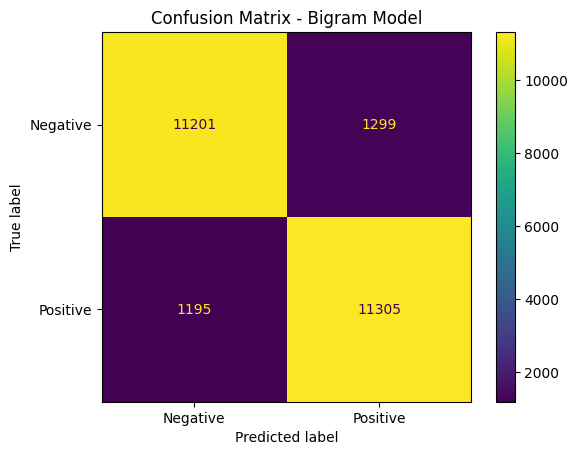

In [ ]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_bigram)

print("Confusion Matrix:")
print(cm)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

display.plot(values_format="d")
plt.title("Confusion Matrix - Bigram Model")
plt.show()


In [ ]:
from google.colab import files
uploaded = files.upload()
